# Chapter 6: knn

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

## 6.1 Introduction & Motivation

Now that we've seen two classification models, it's time to add a third one: knn or *k nearest neighbours*. This model essentials works based on one single question: **When looking at the *k* datapoints closest to me, which label occurs the most?**

This model is easy to understand but can be tricky to tune, especially when it comes to finding the best value for k. In this excercise you will put the model to the test, compare it to the ones you already know and explore new ways to get the best evaluation!

## 6.2 Problem Setting

After a war, often dangerous equipement gets left behind scattered around a field. Over time these can become buried in the earth and lost to time. However, at some point later in time civilians sometimes find still live explosives leading to dangerous situations. Over here in flanders for example, to this day farmers still find live mines from WW 1 when plowing their fields.

To combat this and take out as many of them as possible, a government can take some sonar scans of the ground. The dataset that we are going to explore today contains a series of object, each scanned 60 times with a sonar from different angles. We are trying to predict whether a scanned object is an actual mine 'M' or a rock shaped like a mine 'R'. These values are stored in the 'Material' column.

## 6.3 Model

First, let's have a look at the data.

In [4]:
df = pd.read_csv("Sonar.csv")
df.head()

,Sonar1,Sonar2,Sonar3,Sonar4,Sonar5,Sonar6,Sonar7,Sonar8,Sonar9,Sonar10,...,Sonar52,Sonar53,Sonar54,Sonar55,Sonar56,Sonar57,Sonar58,Sonar59,Sonar60,Material
0,0.0664,0.0575,0.0842,0.0372,0.0458,0.0771,0.0771,0.1130,0.2353,0.1838,...,0.0141,0.0190,0.0043,0.0036,0.0026,0.0024,0.0162,0.0109,0.0079,R
1,0.0094,0.0333,0.0306,0.0376,0.1296,0.1795,0.1909,0.1692,0.1870,0.1725,...,0.0153,0.0112,0.0241,0.0164,0.0055,0.0078,0.0055,0.0091,0.0067,M
2,0.0201,0.0178,0.0274,0.0232,0.0724,0.0833,0.1232,0.1298,0.2085,0.2720,...,0.0131,0.0049,0.0104,0.0102,0.0092,0.0083,0.0020,0.0048,0.0036,M
3,0.0526,0.0563,0.1219,0.1206,0.0246,0.1022,0.0539,0.0439,0.2291,0.1632,...,0.0339,0.0149,0.0335,0.0376,0.0174,0.0132,0.0103,0.0364,0.0208,M
4,0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,...,0.0222,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023,M


In [5]:
dummy_materials = pd.get_dummies(df["Material"], dtype=int)

In [6]:
df = df.drop("Material", axis=1)

df = pd.concat([df, dummy_materials], axis=1)

In [20]:
df.head()

,Sonar1,Sonar2,Sonar3,Sonar4,Sonar5,Sonar6,Sonar7,Sonar8,Sonar9,Sonar10,...,Sonar53,Sonar54,Sonar55,Sonar56,Sonar57,Sonar58,Sonar59,Sonar60,M,R
0,0.0664,0.0575,0.0842,0.0372,0.0458,0.0771,0.0771,0.1130,0.2353,0.1838,...,0.0190,0.0043,0.0036,0.0026,0.0024,0.0162,0.0109,0.0079,0,1
1,0.0094,0.0333,0.0306,0.0376,0.1296,0.1795,0.1909,0.1692,0.1870,0.1725,...,0.0112,0.0241,0.0164,0.0055,0.0078,0.0055,0.0091,0.0067,1,0
2,0.0201,0.0178,0.0274,0.0232,0.0724,0.0833,0.1232,0.1298,0.2085,0.2720,...,0.0049,0.0104,0.0102,0.0092,0.0083,0.0020,0.0048,0.0036,1,0
3,0.0526,0.0563,0.1219,0.1206,0.0246,0.1022,0.0539,0.0439,0.2291,0.1632,...,0.0149,0.0335,0.0376,0.0174,0.0132,0.0103,0.0364,0.0208,1,0
4,0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,...,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023,1,0


In [4]:
df.isna().sum()

Sonar1      0
Sonar2      0
Sonar3      0
Sonar4      0
Sonar5      0
           ..
Sonar57     0
Sonar58     0
Sonar59     0
Sonar60     0
Material    0
Length: 61, dtype: int64

##### Question 1: Try and plot a heatmap to further explore the data. Do you run into any errors? Why is this? How can you solve this using a method we've already seen?

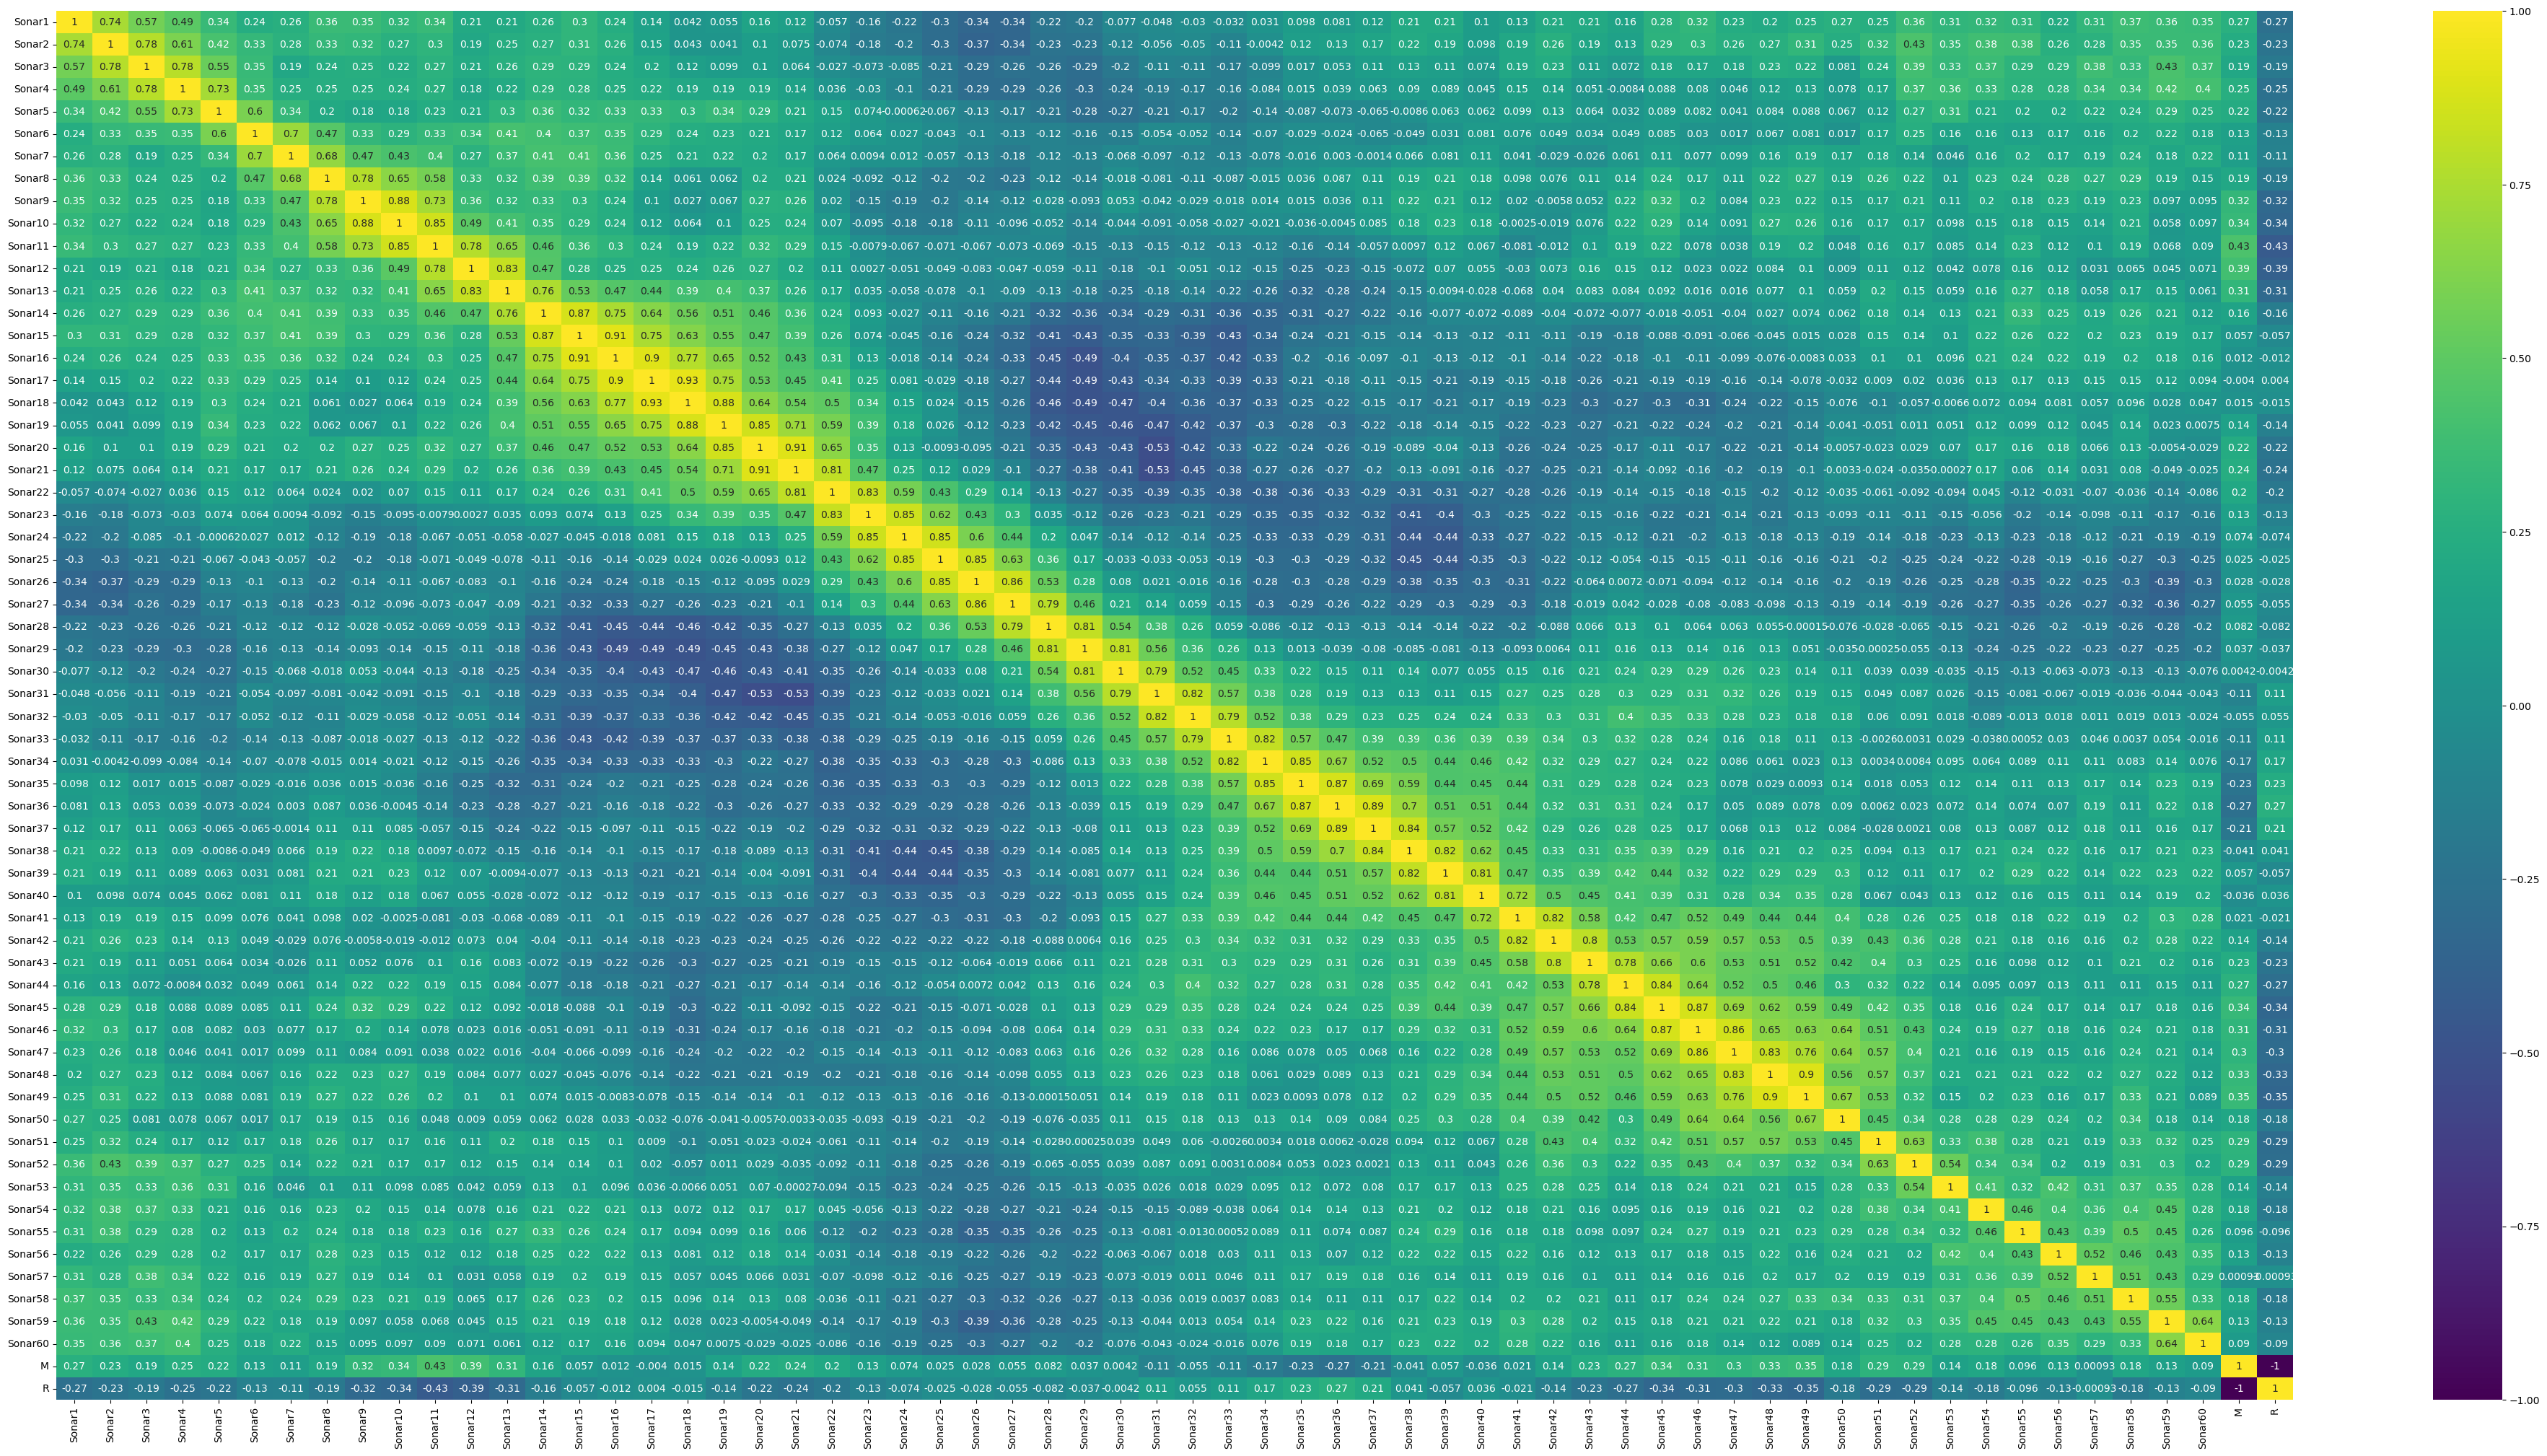

In [7]:
plt.figure(figsize=(50, 25))
sns.heatmap(df.corr(), cmap="viridis", annot=True)

plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")

##### Question 2: Just as always, explore the data by looking at the heatmap. Which variables would you expect to have the highest impact on Material and which ones would you expect to have the lowest impact? Why?

SONAR SCANS WITH THE HIGHEST CORRELATION OF MINE/ROCK

- Sonar 11
- Sonar 12
- Sonar 10
- Sonar 9
- Sonar 13
- Sonar 49
- Sonar 52

##### Question 3: Build and train your model. Make sure to keep some data on the side for testing and to exclude your final column in your training data!

In [8]:
X = df[["Sonar11", "Sonar12", "Sonar10", "Sonar9", "Sonar13", "Sonar49", "Sonar52"]]
y = df["R"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

In [9]:
sonar = []
for i in range(1, 61):
    sonar.append("Sonar" + str(i))

X = df[sonar]
y = df["M"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)

In [10]:
model = KNeighborsClassifier(n_neighbors=9)
model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=9)

In [78]:
accuracy = model.score(X_test, y_test)
accuracy

0.6984126984126984

In [79]:
predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.88      0.58      0.70        38
           1       0.58      0.88      0.70        25

    accuracy                           0.70        63
   macro avg       0.73      0.73      0.70        63
weighted avg       0.76      0.70      0.70        63



##### Question 4: Predict the materials of your testing data. How many rocks are there? And how many mines?

In [80]:
M_Mines = 0
M_Rocks = 0

for thing in predictions:
    if(thing == 1):
        M_Mines += 1
    else:
        M_Rocks += 1

print(f"Amount of rocks: {M_Rocks}")
print(f"Amount of mines: {M_Mines}")

Amount of rocks: 25
Amount of mines: 38


## 6.4 Model Evaluation

Of course our predictions don't mean anything without knowing how good they are. Let's explore this.

##### Question 5: Is your model any good? Elaborate by calculation accuracy and precision.

In [81]:
accuracy = model.score(X_test, y_test)
precision = precision_score(y_test, predictions)

print(f"{accuracy} & {precision}")

0.6984126984126984 & 0.5789473684210527


In [82]:
recall = recall_score(y_test, predictions)
print(recall)

0.88


Evaluation: it's a good model. Accuracy and precision not lower than 75% is good. A high recall score of 88% is also very good, as false positives are prefered over false negatives. Perhaps an ideal recall score would be 90-95% though.

##### Question 6: Can you visually confirm your previous findings by plotting a confusion matrix?

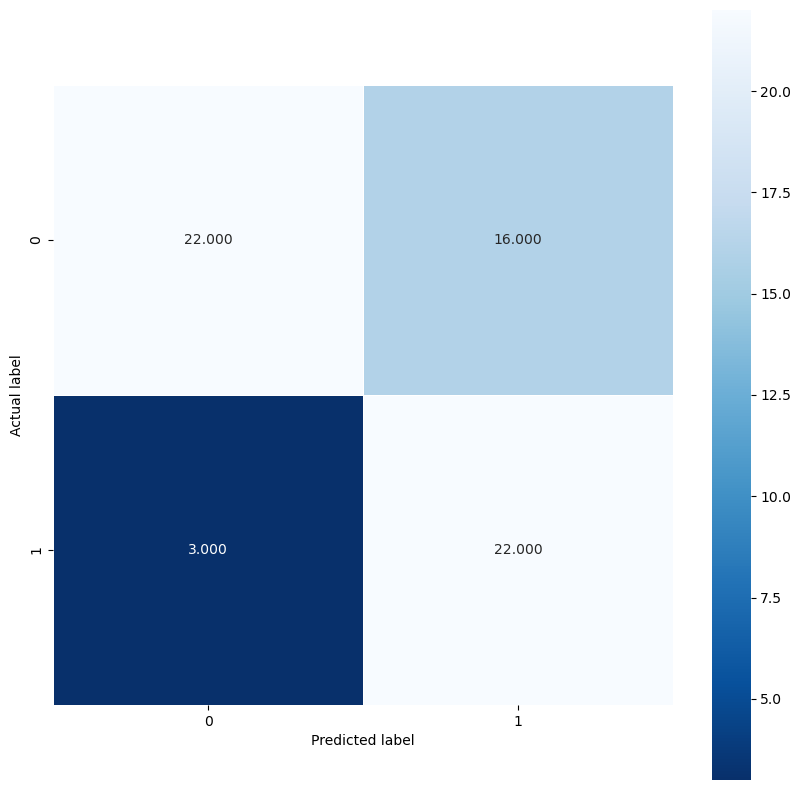

In [83]:
cm = metrics.confusion_matrix(y_test, predictions)
plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

- Most labels were predicted correctly (as expected by the high accuracy score)
- Half more false positives than false negatives, alluding to a higher recall score

##### Question 7: Calculate the other methods we've seen. Are they any good? Elaborate. In the current dataset, would you prefer a high recall or specificity? Why?
*Remember that we are working with a binary solution, not a multiclass solution!*

In [84]:
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
specificity = specificity_score(y_test, predictions)

print(recall, f1, specificity)

0.88 0.6984126984126984 0.5789473684210527


In [44]:
TreeModel = DecisionTreeClassifier()
LogregModel = LogisticRegression()

TreeModel.fit(X_train, y_train)
LogregModel.fit(X_train, y_train)

LogisticRegression()

In [46]:
TreePreds = TreeModel.predict(X_test)
LogregPreds = LogregModel.predict(X_test)

print(f"TREE. Accuracy: {TreeModel.score(X_test, y_test)}. Precision: {precision_score(y_test, TreePreds)}")
print(f"LOGREG. Accuracy: {LogregModel.score(X_test, y_test)}. Precision: {precision_score(y_test, LogregPreds)}")

TREE. Accuracy: 0.6538461538461539. Precision: 0.6
LOGREG. Accuracy: 0.7692307692307693. Precision: 0.7142857142857143


The other models do not seem to be better than the kNN model. Matter a fact they seem to be much worse.

In this case it's much more important to have a high recall score over a specificity score: as it is a lot less dangerous to detect a potential mine that turned out to be a rock, rather than ignoring something we though was a rock turn out to be a mine.

## 6.5 Questions

##### Question 1: See section 6.3

##### Question 2: See section 6.3

##### Question 3: See section 6.3

##### Question 4: See section 6.3

##### Question 5: See section 6.4

##### Question 6: See section 6.4

##### Question 7: See section 6.4

##### Question 8: By default, python will use 5 as the amount of nearest neighbours. Try and find the best value by plotting a series of possible values.

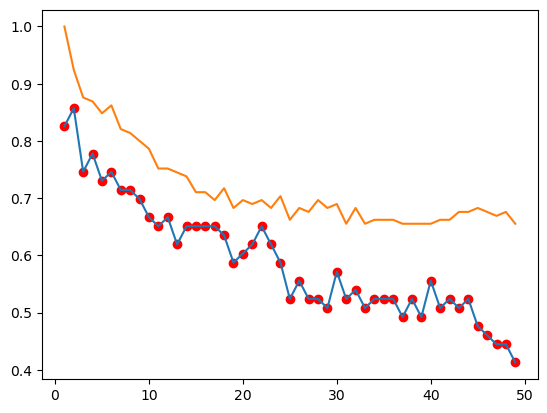

In [12]:
acc_array = []
tacc_array = []
I_array = []

for i in range(1, 50):
    model = KNeighborsClassifier(n_neighbors=i)
    Tmodel = KNeighborsClassifier(n_neighbors=i)

    model.fit(X_train, y_train)
    Tmodel.fit(X_train, y_train)

    acc_array.append(model.score(X_test, y_test))
    tacc_array.append(Tmodel.score(X_train, y_train))
    I_array.append(i)

plt.plot(I_array, acc_array)
plt.plot(I_array, tacc_array)
plt.scatter(I_array, acc_array, color="red")

# Highest accuracy. k = 7

##### Question 9: Do the same for the metric you want to maximize. Does your preferred value for n change? Which value would be 'best' in the end for this data?

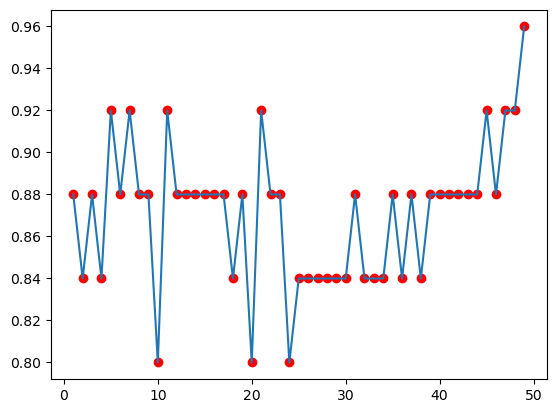

In [88]:
recall_array = []
I_array = []

for i in range(1, 50):
    model = KNeighborsClassifier(n_neighbors=i)
    model.fit(X_train, y_train)
    
    ipreds = model.predict(X_test)
    recall_array.append(recall_score(y_test, ipreds))
    I_array.append(i)

plt.plot(I_array, recall_array)
plt.scatter(I_array, recall_array, color="red")


##### Question 10: Train a logistic regression, decision trees and random forest model on this data. Try and find the best models you can using the methods we've explored in earlier lessons. Which model do you prefer?

##### Question 11: It might just so happen that the test set we are using does not properly represent the whole dataset we have and thus might unfairly favor one model. A way to combat this is called cross validation. Do some research and implement this method using a 10-fold. Does the outcome you found above change?

In [92]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X, y, cv=10)

for score in scores:
    print(score)
print(scores.mean())

0.7142857142857143
0.6190476190476191
0.7142857142857143
0.6190476190476191
0.7142857142857143
0.5714285714285714
0.6190476190476191
0.6666666666666666
0.55
0.7
0.6488095238095238
